# Продвинутый Python, семинар 6

**Лектор:** Садуллаев Музаффар

**Семинаристы:** Садуллаев Музаффар, Бузаев Федор, Дешеулин Олег, Коган Александра, Васина Олеся

**Spoiler Alert:** в рамках курса нельзя изучить ни одну из тем от и до досконально (к сожалению, на это требуется больше времени, чем даже 3 часа в неделю). Но мы попробуем рассказать столько, сколько возможно :)

![](https://www.sqlitetutorial.net/wp-content/uploads/2015/11/sqlite-sample-database-color.jpg)

Обозначения на схеме

[Статья на практикуме](https://practicum.yandex.ru/blog/chto-takoe-er-diagramma/)

Чтобы грамотно спроектировать какую-либо базу данных, надо сперва хорошо разобраться в предметной области, данные из которой будет хранить наша база данных. Предметную область сперва надо смоделировать с помощью ER модели (Entity-Relationship, Сущность-Связь), которав показывает взаимосвязи между разными сущностями предметной области. Изучим терминологию касаемо построения ER моделей:

***Сущность / Entity*** - понятие в предметной области (например, если мы проектируем БД для хранения информации о студентах в университете, то в этом случае сущностями будут студент, преподаватель, дисциплина, учебный план и тд)

***Экземляр сущности*** - конкретный представитель сущности (например, студент Вася, студент Маша, студент Коля и тд)

Каждая сущность имеет свои ***атрибуты*** - характеристики (например, у студента это ФИО, дата рождения, курс обучения, специальность и тд).

У каждого экземпляра сущности есть свои уникальные значения атрибутов, то есть два экземпляра сущности отличаются значением хотя бы одного атрибута (например, два студента отличаются датой рождения).

Прописав все сущности в предметной области, надо выяснить взаимосвязи между ними. Существуют несколько видов взаимосвязей:

1) 1:1 = один к одному: каждому экзмепляру одной сущности соответствует ровно 1 экземпляр другой сущности (например, у каждого студента есть только одна зачётка, а каждая зачётка принадлежит ровно одному студенту)

2) 1:М = один ко многим: каждому экзмепляру одной сущности соответствует несколько экземпляров другой сущности, а одному экзмепляру другой сущности соотвествует только один экзмепляр первой сущности (например, каждый преподаватель может вести лекции по нескольким дисциплинам, но лекции по каждой дисциплине читаются только одним преподавателем)

3) М:М = многие ко многим: каждому экземпляру первой сущности соответствует несколько экземпляров второй сущности и каждому экземпляру второй сущности соответствует несколько экземпляров первой сущности (например, каждый студент может посещать лекции по нескольким дисциплинам и каждая дисциплина читается для нескольких студентов)

Эти связи внутри ER-модели могут быть представлены на ER-диаграмме. Способы представления на диаграмме бывают разные, то есть существуют разные нотации:

*   Нотация Чена / UML (unified modeling language):

    - сущности отображаются прямоугольниками

    - атрибуты отображаются овалами

    - названия связей отображают с помощью ромбов

    - связи между сущностями отображают линиями с надписями-цифрами, характеризующими тип связи

    - часто используют для построения концептуальных моделей, то есть когда надо верхнеуровнево показать связи между сущностями, не вникая в их атрибуты



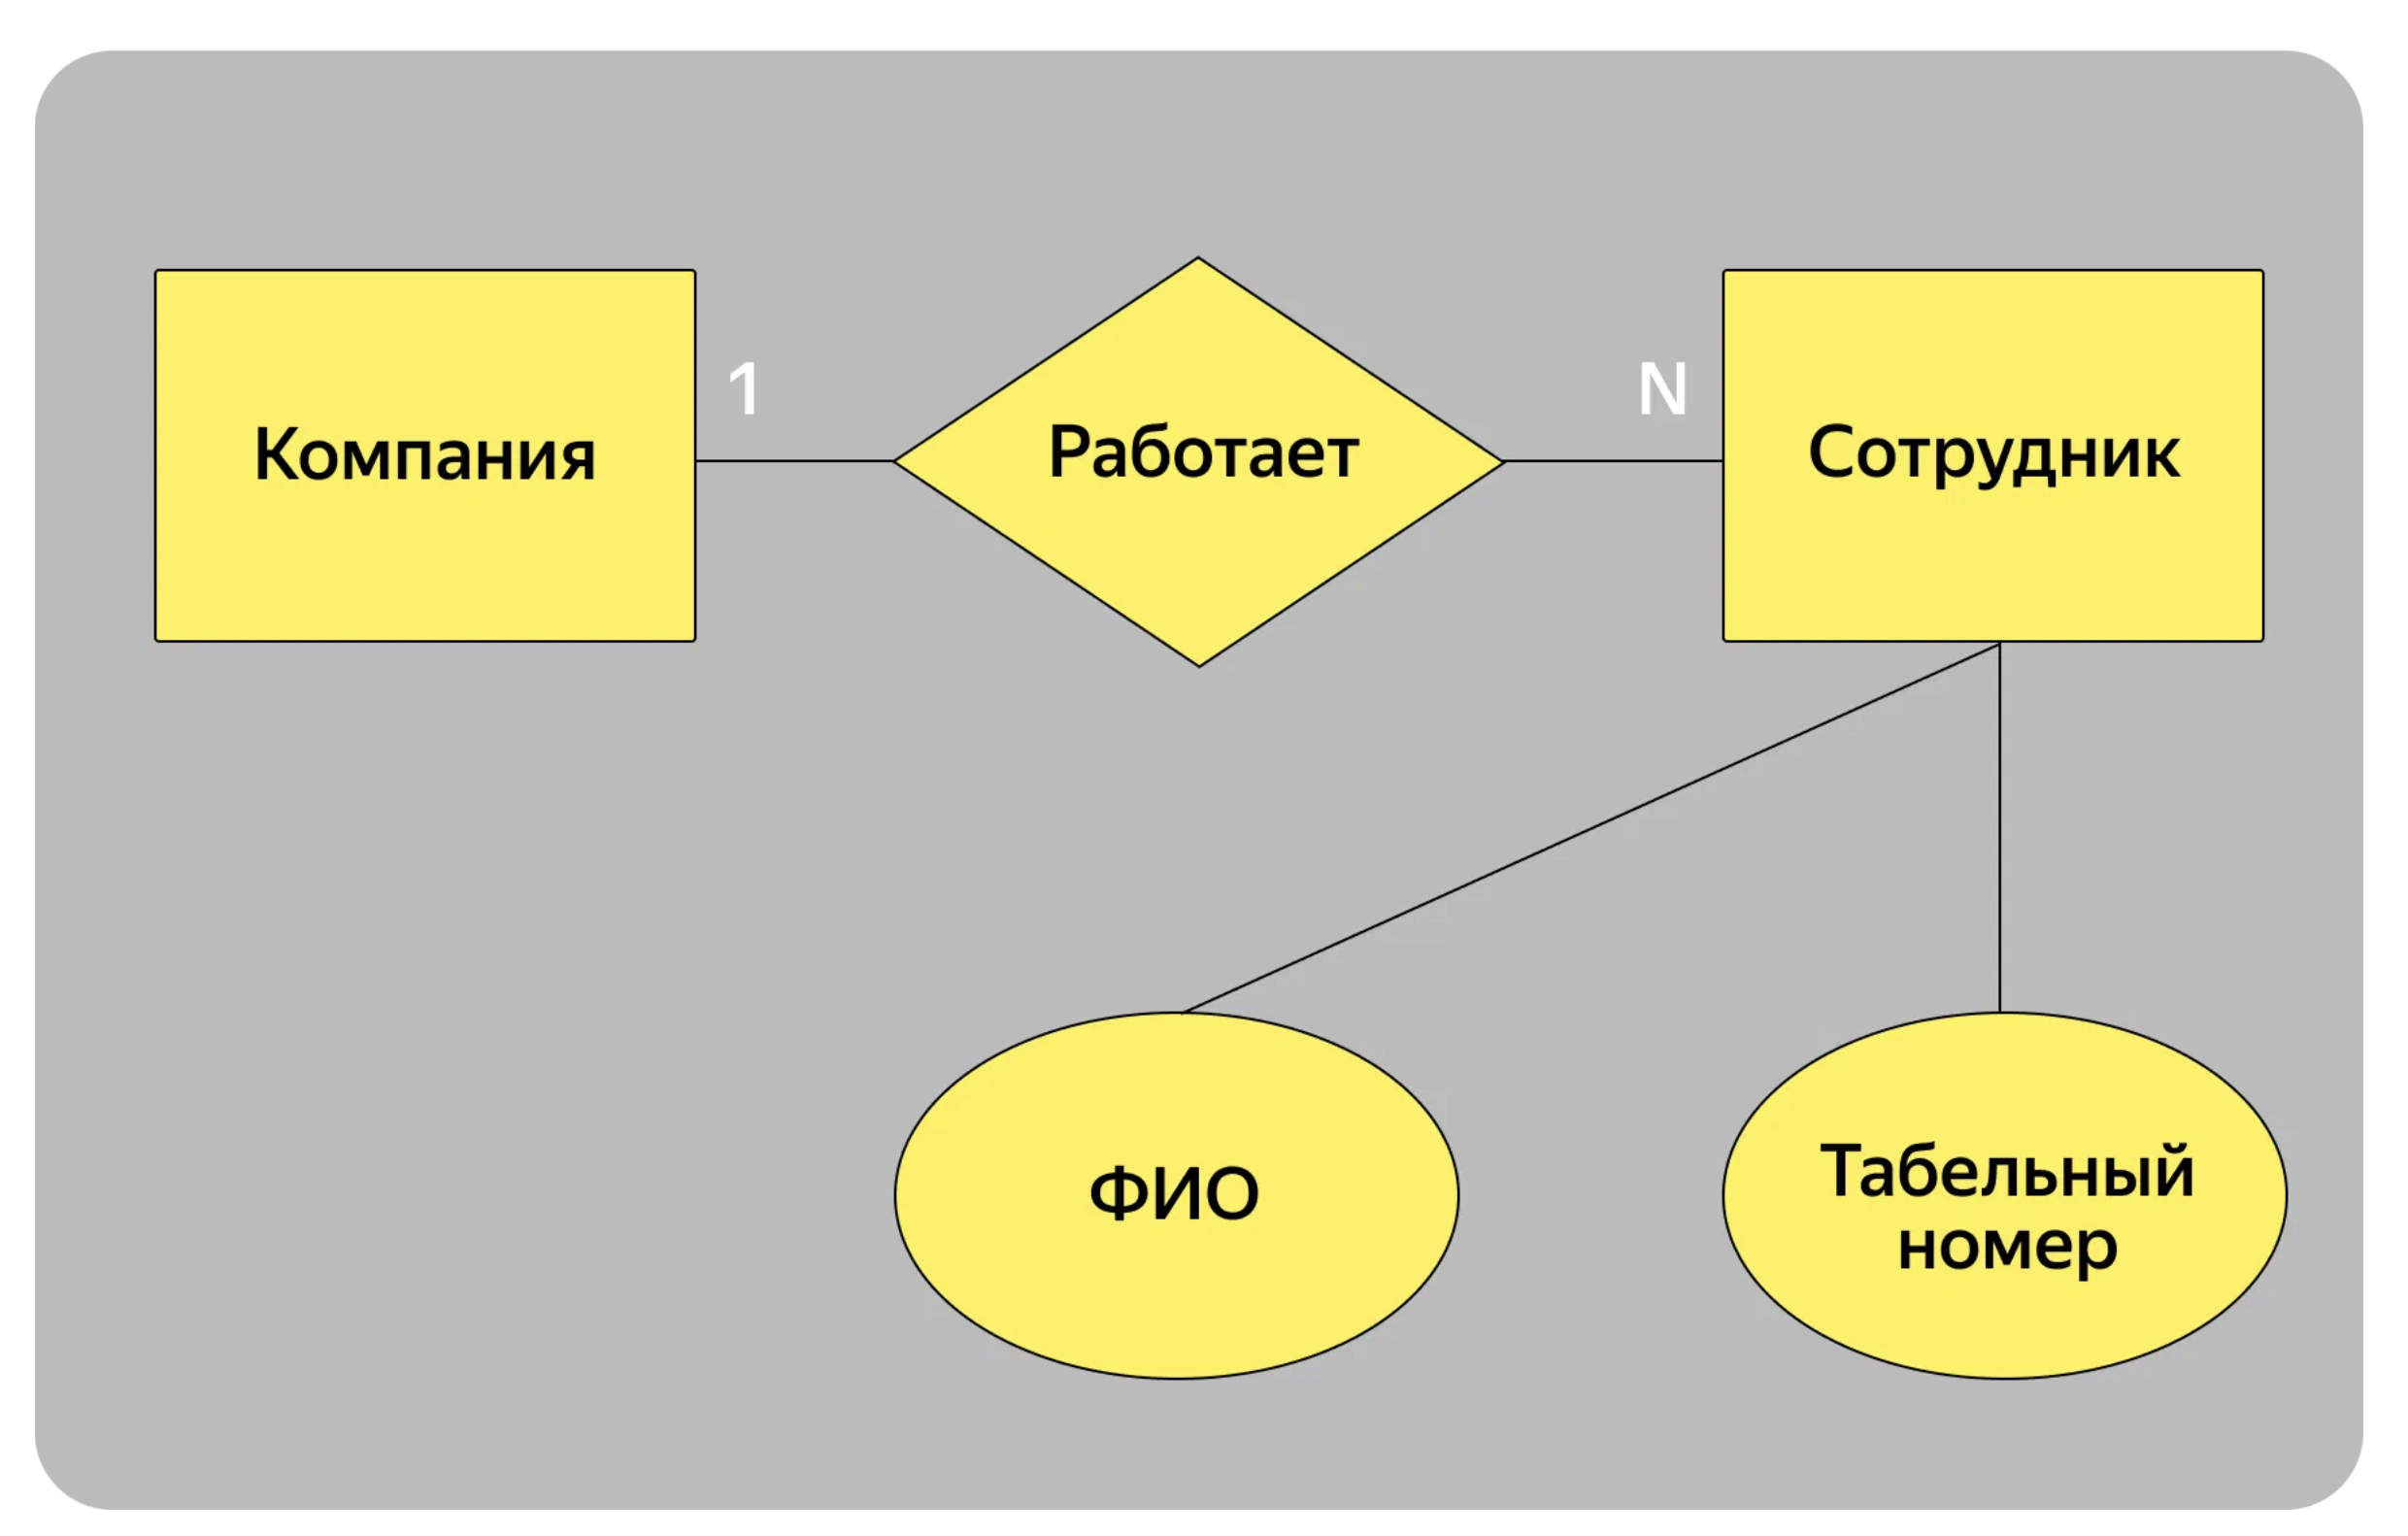


* Нотация Мартина / Crow's Foot / Воронья лапка:

    - сущности отображают прямоугольником

    - атрибуты перечисляют под сущностью

    - связи обозначают линиями

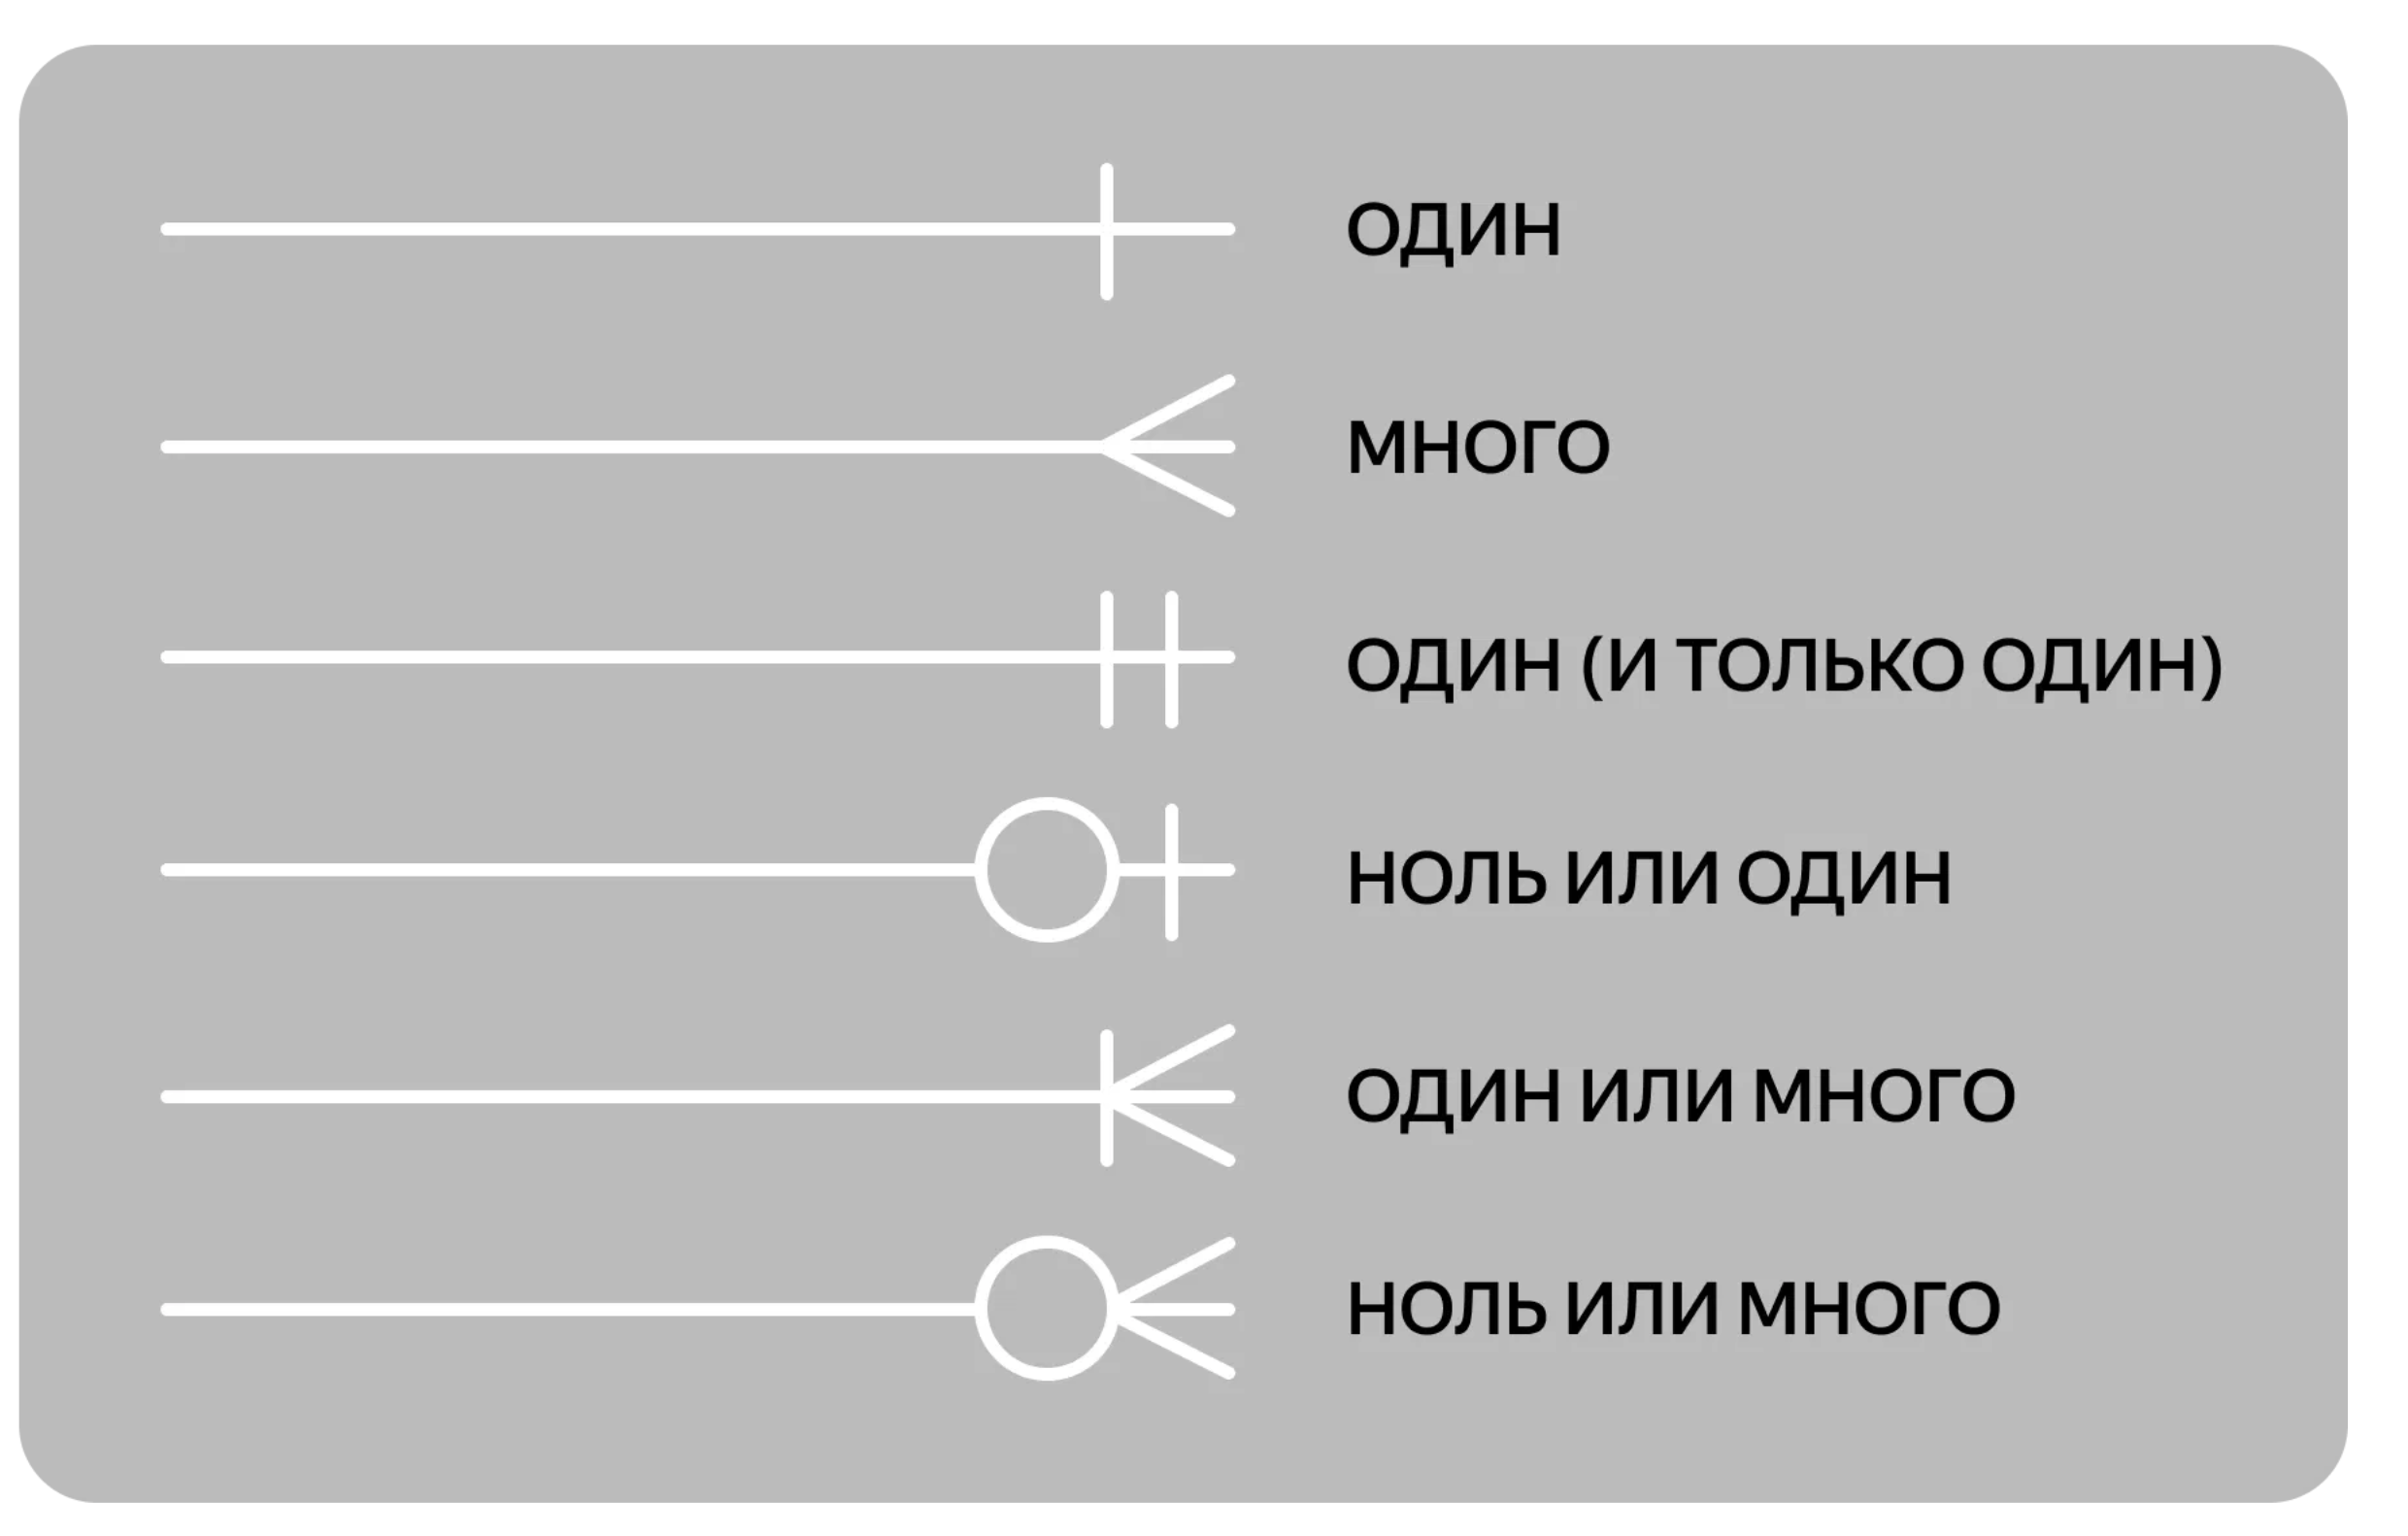

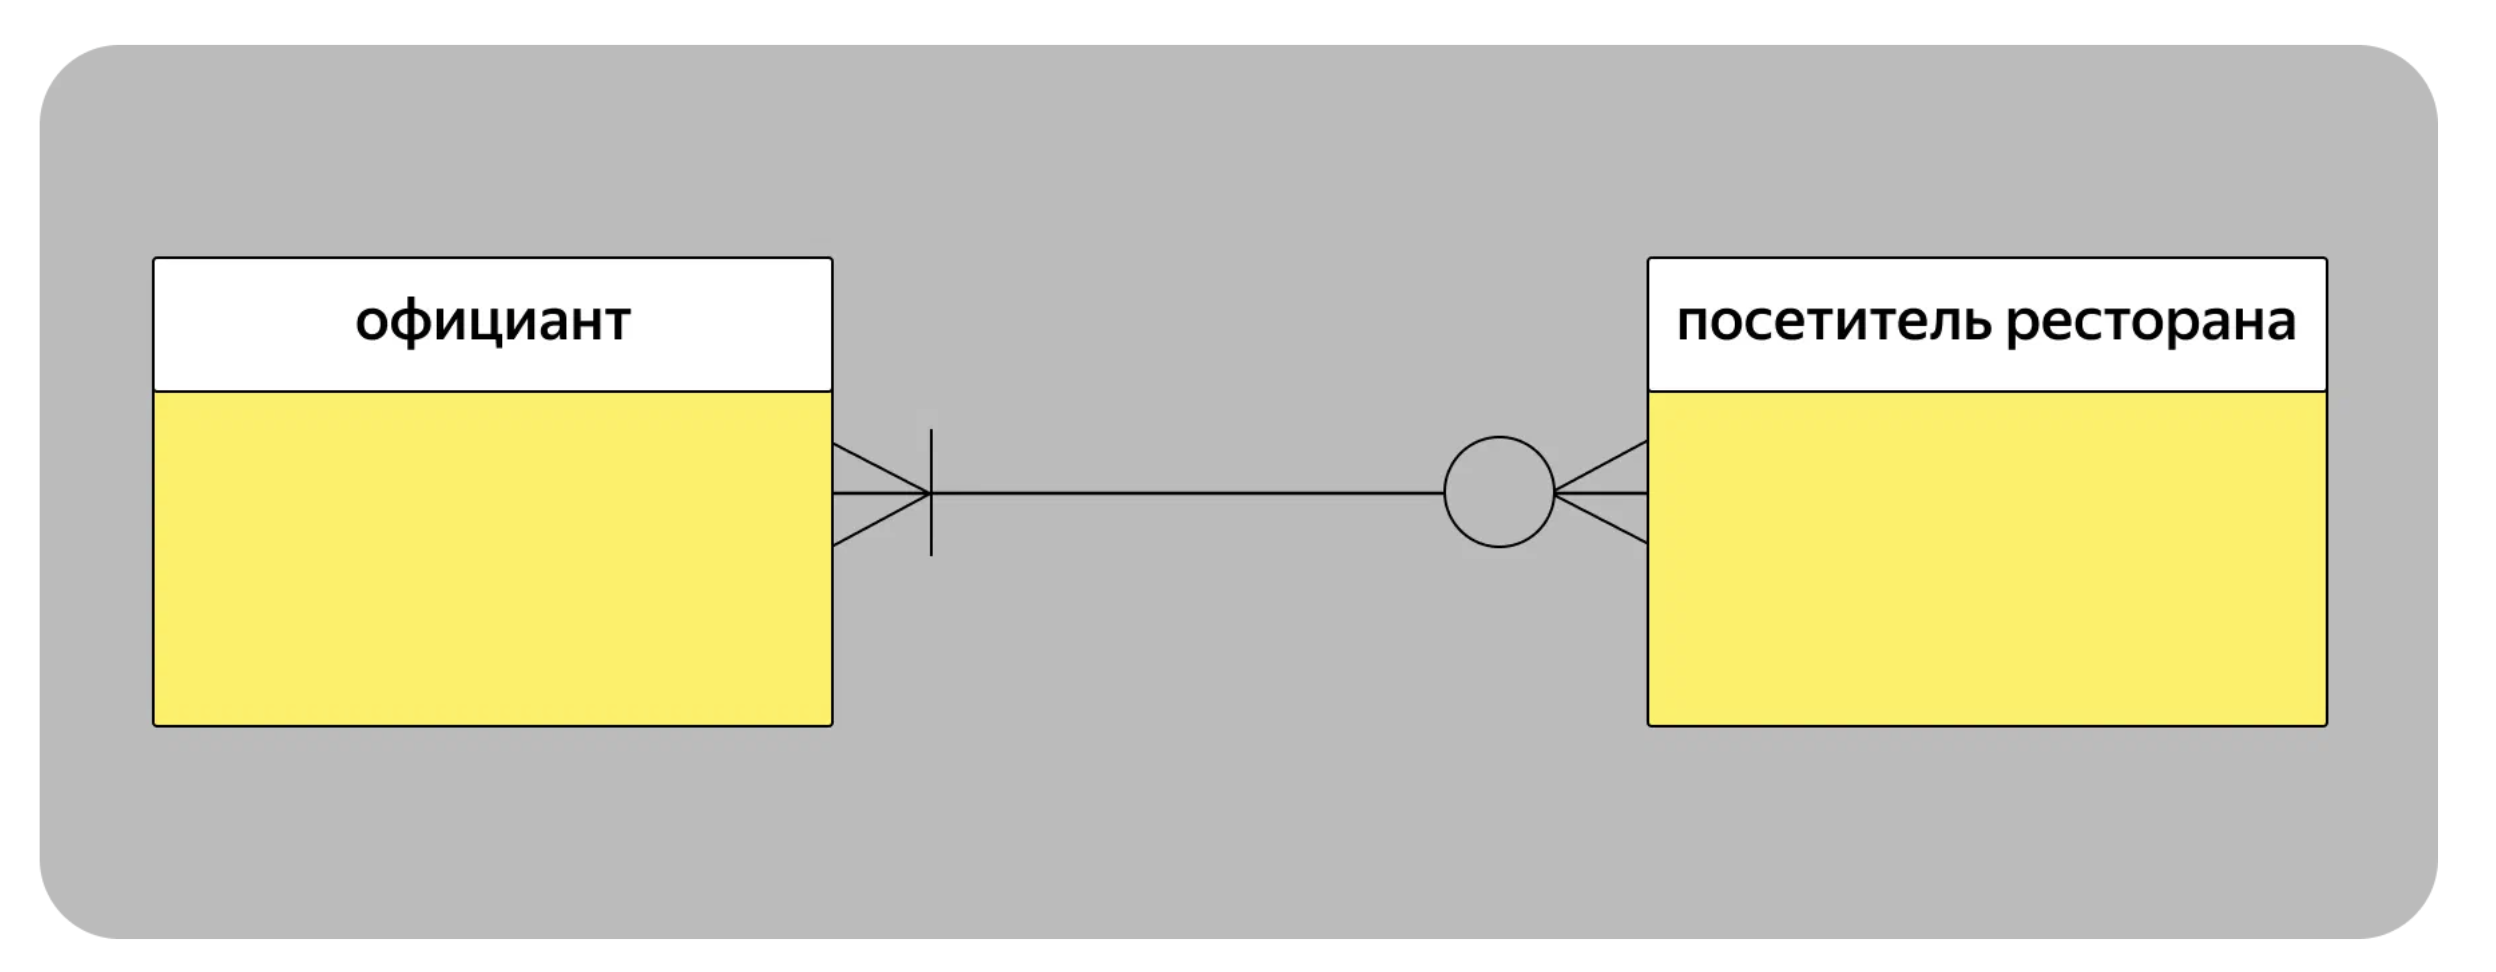

***SQL PRIMARY KEY*** - это столбец(цы) в таблице, который(ые) должен(ны) содержать уникальное значение, которое можно использовать для уникальной идентификации каждой строки таблицы. (например, если таблица хранит информацию о студенте, то первичным ключом может быть, например, совокупность столбцов с ФИО и датой рождения; либо может быть один столбец с уникальным ID студента, что чаще и встречается).  

Для данной таблицы можно определить только один PRIMARY KEY.

***FOREIGN KEY*** - внешний ключ, это столбец(цы) в таблице, которые ссылаются на столбец(цы) другой таблицы, в которой они являются первичным ключом (например, если есть таблица с информацией о студенте, в которой первичным ключом является ID студента, и есть таблица с информацией о записи студентов на курсы, то в ней будут строки с ID дисциплины и ID студентов, которые на неё записаны; так вот ID студентов будут являться внешними ключами, потому что они ссылаются на первичный ключ в таблице с информацией о студентах).

 Это очень мощное средство для обеспечения ссылочной целостности между таблицами, которое позволяет не только следить за наличиями правильных ссылок, но и автоматически управлять ими.

In [ ]:
!wget https://github.com/Palladain/Deep_Python_2023/raw/main/week07/chinook.db

--2025-10-18 12:04:23--  https://github.com/Palladain/Deep_Python_2023/raw/main/week07/chinook.db
Resolving github.com (github.com)... 140.82.114.4
Connecting to github.com (github.com)|140.82.114.4|:443... connected.
HTTP request sent, awaiting response... 302 Found
Location: https://raw.githubusercontent.com/Palladain/Deep_Python_2023/main/week07/chinook.db [following]
--2025-10-18 12:04:24--  https://raw.githubusercontent.com/Palladain/Deep_Python_2023/main/week07/chinook.db
Resolving raw.githubusercontent.com (raw.githubusercontent.com)... 185.199.108.133, 185.199.109.133, 185.199.110.133, ...
Connecting to raw.githubusercontent.com (raw.githubusercontent.com)|185.199.108.133|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 884736 (864K) [application/octet-stream]
Saving to: ‘chinook.db’

chinook.db          100%[===================>] 864.00K  --.-KB/s    in 0.07s   

2025-10-18 12:04:24 (12.7 MB/s) - ‘chinook.db’ saved [884736/884736]



**Основные понятия**

SQLite — это встроенная, лёгкая база данных, хранящая всё в одном файле.
Модуль sqlite3 позволяет:

- создавать и подключаться к базе данных,

- выполнять SQL-запросы,

- извлекать, изменять и удалять данные,

- работать с транзакциями.

In [ ]:
import sqlite3

In [ ]:
connection = sqlite3.connect("chinook.db") # открыли

In [ ]:
# Подключение к файлу базы данных (создастся, если не существует)
conn = sqlite3.connect("example.db")

# Если хочешь, чтобы база была временной (в памяти):
# conn = sqlite3.connect(":memory:")

**Курсор (cursor)**

Курсор — это объект, через который выполняются SQL-запросы.
Он создаётся через подключение (Connection)

In [ ]:
cursor = connection.cursor()

**Основные методы курсора**


```
| Метод                             | Описание                                                               |
| --------------------------------- | ---------------------------------------------------------------------- |
| `execute(sql, params=None)`       | Выполняет один SQL-запрос                                              |
| `executemany(sql, seq_of_params)` | Выполняет один SQL-запрос для множества наборов параметров             |
| `executescript(sql_script)`       | Выполняет несколько SQL-запросов сразу (например, много CREATE/INSERT) |
| `fetchone()`                      | Возвращает одну строку результата                                      |
| `fetchall()`                      | Возвращает все строки результата                                       |
| `fetchmany(size)`                 | Возвращает указанное количество строк                                  |
| `lastrowid`                       | Возвращает ID последней вставленной записи                             |
| `rowcount`                        | Количество строк, затронутых последним запросом                        |

```



Методы соединения (Connection)



```
| Метод             | Описание                                                     |
| ----------------- | ------------------------------------------------------------ |
| `cursor()`        | Создаёт курсор                                               |
| `commit()`        | Сохраняет изменения                                          |
| `rollback()`      | Отменяет последние изменения (если не закоммичено)           |
| `close()`         | Закрывает соединение                                         |
| `execute()`       | Упрощённый способ выполнить SQL без создания курсора вручную |
| `executemany()`   | Аналогично, но для множественных запросов                    |
| `executescript()` | Выполнить несколько SQL-запросов подряд                      |

```



In [ ]:
# Как посмотреть все таблицы в БД?

sql_query = """SELECT name FROM sqlite_master
    WHERE type='table';"""


cursor.execute(sql_query)
print("List of tables \n")

print(cursor.fetchall())

List of tables 

[('albums',), ('sqlite_sequence',), ('artists',), ('customers',), ('employees',), ('genres',), ('invoices',), ('invoice_items',), ('media_types',), ('playlists',), ('playlist_track',), ('tracks',), ('sqlite_stat1',)]


In [ ]:
# извлечь вообще все данные, как таблицы, так и метаданные
sql_query = """SELECT * FROM sqlite_master;"""

cursor.execute(sql_query)


print(cursor.fetchone())

('table', 'albums', 'albums', 2, 'CREATE TABLE "albums"\r\n(\r\n    [AlbumId] INTEGER PRIMARY KEY AUTOINCREMENT NOT NULL,\r\n    [Title] NVARCHAR(160)  NOT NULL,\r\n    [ArtistId] INTEGER  NOT NULL,\r\n    FOREIGN KEY ([ArtistId]) REFERENCES "artists" ([ArtistId]) \r\n\t\tON DELETE NO ACTION ON UPDATE NO ACTION\r\n)')


In [ ]:
!pip install tabulate

In [ ]:
from tabulate import tabulate

sql_query = """SELECT * FROM albums;"""

cursor.execute(sql_query)

rows = cursor.fetchall()
headers = [description[0] for description in cursor.description]  # имена колонок
print(tabulate(rows[:10], headers=headers, tablefmt="grid"))

+-----------+---------------------------------------+------------+
|   AlbumId | Title                                 |   ArtistId |
+===========+=======================================+============+
|         1 | For Those About To Rock We Salute You |          1 |
+-----------+---------------------------------------+------------+
|         2 | Balls to the Wall                     |          2 |
+-----------+---------------------------------------+------------+
|         3 | Restless and Wild                     |          2 |
+-----------+---------------------------------------+------------+
|         4 | Let There Be Rock                     |          1 |
+-----------+---------------------------------------+------------+
|         5 | Big Ones                              |          3 |
+-----------+---------------------------------------+------------+
|         6 | Jagged Little Pill                    |          4 |
+-----------+---------------------------------------+---------

In [ ]:
sql_query = """SELECT * FROM tracks;"""

cursor.execute(sql_query)


rows = cursor.fetchall()
headers = [description[0] for description in cursor.description]  # имена колонок
print(tabulate(rows[:20], headers=headers, tablefmt="grid"))

+-----------+-----------------------------------------+-----------+---------------+-----------+------------------------------------------------------------------------+----------------+----------+-------------+
|   TrackId | Name                                    |   AlbumId |   MediaTypeId |   GenreId | Composer                                                               |   Milliseconds |    Bytes |   UnitPrice |
+===========+=========================================+===========+===============+===========+========================================================================+================+==========+=============+
|         1 | For Those About To Rock (We Salute You) |         1 |             1 |         1 | Angus Young, Malcolm Young, Brian Johnson                              |         343719 | 11170334 |        0.99 |
+-----------+-----------------------------------------+-----------+---------------+-----------+-------------------------------------------------------------

In [ ]:
sql_query = """SELECT * FROM artists;"""

cursor.execute(sql_query)


rows = cursor.fetchall()
headers = [description[0] for description in cursor.description]  # имена колонок
print(tabulate(rows[:20], headers=headers, tablefmt="grid"))

+------------+-----------------------------+
|   ArtistId | Name                        |
+============+=============================+
|          1 | AC/DC                       |
+------------+-----------------------------+
|          2 | Accept                      |
+------------+-----------------------------+
|          3 | Aerosmith                   |
+------------+-----------------------------+
|          4 | Alanis Morissette           |
+------------+-----------------------------+
|          5 | Alice In Chains             |
+------------+-----------------------------+
|          6 | Antônio Carlos Jobim        |
+------------+-----------------------------+
|          7 | Apocalyptica                |
+------------+-----------------------------+
|          8 | Audioslave                  |
+------------+-----------------------------+
|          9 | BackBeat                    |
+------------+-----------------------------+
|         10 | Billy Cobham                |
+---------

In [ ]:
# 1. Вывести все альбомы AC/DC
# 2. Вывести все треки AC/DC
# 3. Вывести название плейлиста, количество треков
# 4. Вывести треки без привязанных альбомов
# 5. Найти все жанры и количество треков в каждом жанре
# 6. Найти плейлисты, которые не содержат ни одного трека

[('For Those About To Rock We Salute You',), ('Let There Be Rock',)]


In [ ]:
# 1. Вывести все альбомы AC/DC

sql_query = """
      SELECT albums.title, albums.ArtistId

      FROM albums
      JOIN artists ON albums.ArtistId = artists.ArtistId
      WHERE Name = 'AC/DC';"""

cursor.execute(sql_query)

for row in cursor.fetchall():
  print(row, "\n")


('For Those About To Rock We Salute You', 1) 

('Let There Be Rock', 1) 



In [ ]:
# 2. Вывести все треки AC/DC

sql_query = """
      SELECT tracks.Name, artists.Name

      FROM tracks
      JOIN albums ON tracks.AlbumId = albums.AlbumId
      JOIN artists ON albums.ArtistId = artists.ArtistId
      WHERE artists.Name = 'AC/DC';"""

cursor.execute(sql_query)


for row in cursor.fetchall():
  print(row, "\n")

('For Those About To Rock (We Salute You)', 'AC/DC') 

('Put The Finger On You', 'AC/DC') 

("Let's Get It Up", 'AC/DC') 

('Inject The Venom', 'AC/DC') 

('Snowballed', 'AC/DC') 

('Evil Walks', 'AC/DC') 

('C.O.D.', 'AC/DC') 

('Breaking The Rules', 'AC/DC') 

('Night Of The Long Knives', 'AC/DC') 

('Spellbound', 'AC/DC') 

('Go Down', 'AC/DC') 

('Dog Eat Dog', 'AC/DC') 

('Let There Be Rock', 'AC/DC') 

('Bad Boy Boogie', 'AC/DC') 

('Problem Child', 'AC/DC') 

('Overdose', 'AC/DC') 

("Hell Ain't A Bad Place To Be", 'AC/DC') 

('Whole Lotta Rosie', 'AC/DC') 



In [ ]:
# 3. Вывести название плейлиста, количество треков

sql_query = """
      SELECT playlists.Name, COUNT(playlist_track.TrackId) AS cnt

      FROM playlists
      JOIN playlist_track ON playlists.PlaylistId = playlist_track.PlaylistId
      GROUP BY playlists.Name;
      """

cursor.execute(sql_query)

rows = cursor.fetchall()
headers = [description[0] for description in cursor.description]  # имена колонок
print(tabulate(rows, headers=headers, tablefmt="grid"))

+----------------------------+-------+
| Name                       |   cnt |
+============================+=======+
| 90’s Music                 |  1477 |
+----------------------------+-------+
| Brazilian Music            |    39 |
+----------------------------+-------+
| Classical                  |    75 |
+----------------------------+-------+
| Classical 101 - Deep Cuts  |    25 |
+----------------------------+-------+
| Classical 101 - Next Steps |    25 |
+----------------------------+-------+
| Classical 101 - The Basics |    25 |
+----------------------------+-------+
| Grunge                     |    15 |
+----------------------------+-------+
| Heavy Metal Classic        |    26 |
+----------------------------+-------+
| Music                      |  6580 |
+----------------------------+-------+
| Music Videos               |     1 |
+----------------------------+-------+
| On-The-Go 1                |     1 |
+----------------------------+-------+
| TV Shows               

In [ ]:
# 4. Вывести треки без привязанных альбомов
sql_query = """
    SELECT
        tracks.Name,
        albums.Title
    FROM tracks
    LEFT JOIN albums ON tracks.AlbumId = albums.AlbumId
    WHERE albums.AlbumId IS NULL;
"""

cursor.execute(sql_query)

print(cursor.fetchall())

[]


In [ ]:
# 5. Найти все жанры и количество треков в каждом жанре

sql_query = """
    SELECT
        genres.Name,
        COUNT(tracks.TrackId)
    FROM genres
    LEFT JOIN tracks ON genres.GenreId = tracks.GenreId
    GROUP BY genres.Name;

"""

cursor.execute(sql_query)


rows = cursor.fetchall()
headers = [description[0] for description in cursor.description]  # имена колонок
print(tabulate(rows, headers=headers, tablefmt="grid"))

+--------------------+-------------------------+
| Name               |   COUNT(tracks.TrackId) |
+====================+=========================+
| Alternative        |                      40 |
+--------------------+-------------------------+
| Alternative & Punk |                     332 |
+--------------------+-------------------------+
| Blues              |                      81 |
+--------------------+-------------------------+
| Bossa Nova         |                      15 |
+--------------------+-------------------------+
| Classical          |                      74 |
+--------------------+-------------------------+
| Comedy             |                      17 |
+--------------------+-------------------------+
| Drama              |                      64 |
+--------------------+-------------------------+
| Easy Listening     |                      24 |
+--------------------+-------------------------+
| Electronica/Dance  |                      30 |
+-------------------

In [ ]:
# 6. Найти плейлисты, которые не содержат ни одного трека

sql_query = """
    SELECT
        playlists.Name,
        COUNT(playlist_track.TrackId)
    FROM playlists
    LEFT JOIN playlist_track ON playlists.PlaylistId = playlist_track.PlaylistId
    GROUP BY playlists.PlaylistId
    HAVING COUNT(playlist_track.TrackId) = 0;
"""

cursor.execute(sql_query)


rows = cursor.fetchall()
headers = [description[0] for description in cursor.description]  # имена колонок
print(tabulate(rows, headers=headers, tablefmt="grid"))

+------------+---------------------------------+
| Name       |   COUNT(playlist_track.TrackId) |
+============+=================================+
| Movies     |                               0 |
+------------+---------------------------------+
| Audiobooks |                               0 |
+------------+---------------------------------+
| Audiobooks |                               0 |
+------------+---------------------------------+
| Movies     |                               0 |
+------------+---------------------------------+


In [ ]:
sql_query = """
    SELECT
        *
    FROM playlists
    WHERE playlists.Name = 'Movies'
"""

cursor.execute(sql_query)


print(cursor.fetchall())

[(2, 'Movies'), (7, 'Movies')]


Главное отличие HAVING от WHERE в том, что в HAVING можно наложить условия на результаты группировки, потому что порядок исполнения запроса устроен таким образом, что на этапе, когда выполняется WHERE, ещё нет групп, а HAVING выполняется уже после формирования групп.

## Работаем с ORM

ORM (Object Relational Mapping / Объектно-реляционное отображение) - программная технология, которая позволяет взаимодействовать с базами данных с использованием принципов ООП. Вместо того чтобы писать SQL-запросы напрямую для работы с данными в базе данных, можно использовать ORM, чтобы взаимодействовать с данными, как если бы они были объектами в коде. То есть мы абстрагируемся от сырых SQL запросов.

SQLAlchemy - набор тулов для работы с БД в Python. Этот набор организован в два раздельных API: Core и ORM (https://docs.sqlalchemy.org/en/20/index.html)

- Core есть библиотека для обеспечения подключения к БД, управления запросами к ней и получения результатов:

    - Engine управляет соединением с БД: содержит пул соединений и умеет выполнять запросы к БД, используя DB API;

    - Schema может создавать таблицы, столбцы в таблицах, мета данные, то есть задавать их структуру для последующего отражения в физической БД

    - SQL Expression language - инструмент программной генерации запросов к БД: он генериует корректный SQL запрос для корректного диалекта (PostgreSQL, SQLite)

- ORM есть библиотека, которая использует внутри себя Corе и непосредственно реализует возможности технологии ORM.

Выглядит это вот так:

![](https://s3.amazonaws.com/media-p.slid.es/uploads/10882/images/5116660/sqlalchemy__3_.png)

Есть и другие фреймворки для работы с ORM:

1. Django ORM: https://docs.djangoproject.com/en/5.1/topics/db/models/
2. Pony ORM: https://docs.ponyorm.org/
3. Pewee: https://docs.peewee-orm.com/en/latest/#

Установим нужные зависимости

In [ ]:
!pip install pypika
!pip install sqlalchemy

Прежде чем мы начнем делать SQL-запросы давайте подготовим сущности над объектами БД

In [ ]:
from sqlalchemy import create_engine, Column, Integer, String, ForeignKey, Table, Float
from sqlalchemy.orm import relationship, declarative_base, sessionmaker

In [ ]:
# создаём объект специального базового класса, от котого будем наследовать свои классы
Base = declarative_base() # https://docs.sqlalchemy.org/en/20/orm/declarative_styles.html

In [ ]:
class Playlist(Base):
    __table_args__ = {'extend_existing': True}
    __tablename__ = 'playlists'

    PlaylistId = Column(Integer, primary_key=True)
    Name = Column(String)

    tracks = relationship('Track', secondary='playlist_track', back_populates='playlists')

Давайте поподробнее что мы тут сделали:

Здесь мы указали сущность плейлиста. Почему это называется сущностью?

Оно отнаследовалось от класса Base. В контексте ORM все сущности наследуются от него. К тому же мы указали название таблицы в котором оно определяется.

Так как у таблиц есть отношения с другими таблицами также мы определили `relationship` с другой таблицей.

В текущем примере мы создали отношение `Many-To-Many` (см. первую картинку) которое реализовано через промежуточную таблицу `playlist_track`. Это означает, что один плейлист может содержать много треков, а один трек может включен в несколько плейлистов.

Сделаем такое же для остальных сущностей

In [ ]:
class Genre(Base):
    __tablename__ = 'genres'

    GenreId = Column(Integer, primary_key=True)
    Name = Column(String)

    # Отношение "Один жанр" - "много треков"
    tracks = relationship('Track', back_populates='genre')

In [ ]:
class Track(Base):
    __tablename__ = 'tracks'

    TrackId = Column(Integer, primary_key=True)
    Name = Column(String)
    AlbumId = Column(Integer, ForeignKey('albums.AlbumId'))
    GenreId = Column(Integer, ForeignKey('genres.GenreId'))
    Composer = Column(String)
    Milliseconds = Column(Integer)
    Bytes = Column(Integer)
    UnitPrice = Column(Float)

    # Отношение "много треков" - "один жанр"
    genre = relationship('Genre', back_populates='tracks')
    # Отношение "много треков" - "один альбом"
    album = relationship('Album', back_populates='tracks')
    # Отношение "много треков" - "много плейлистов"
    playlists = relationship('Playlist', secondary='playlist_track', back_populates='tracks')
    # Отношение "Один трек" - "много счетов"
    invoice_items = relationship('InvoiceItem', back_populates='track')

In [ ]:
class Album(Base):
    __tablename__ = 'albums'

    AlbumId = Column(Integer, primary_key=True)
    Title = Column(String)
    ArtistId = Column(Integer, ForeignKey('artists.ArtistId'))

    artist = relationship('Artist', back_populates='albums')
    tracks = relationship('Track', back_populates='album')

In [ ]:
class Artist(Base):
    __tablename__ = 'artists'

    ArtistId = Column(Integer, primary_key=True)
    Name = Column(String)

    albums = relationship('Album', back_populates='artist')

In [ ]:
class InvoiceItem(Base):
    __tablename__ = 'invoice_items'

    InvoiceLineId = Column(Integer, primary_key=True)
    InvoiceId = Column(Integer, ForeignKey('invoices.InvoiceId'))
    TrackId = Column(Integer, ForeignKey('tracks.TrackId'))
    UnitPrice = Column(Float)
    Quantity = Column(Integer)

    track = relationship('Track', back_populates='invoice_items')
    invoice = relationship('Invoice', back_populates='invoice_items')

In [ ]:
class Invoice(Base):
    __tablename__ = 'invoices'

    InvoiceId = Column(Integer, primary_key=True)
    CustomerId = Column(Integer, ForeignKey('customers.CustomerId'))
    Total = Column(Float)

    customer = relationship('Customer', back_populates='invoices')
    invoice_items = relationship('InvoiceItem', back_populates='invoice')

In [ ]:
class Customer(Base):
    __tablename__ = 'customers'

    CustomerId = Column(Integer, primary_key=True)
    FirstName = Column(String)
    LastName = Column(String)
    Email = Column(String)
    Address = Column(String)
    City = Column(String)
    State = Column(String)
    Country = Column(String)
    PostalCode = Column(String)

    invoices = relationship('Invoice', back_populates='customer')

In [ ]:
class PlaylistTrack(Base):
    __table_args__ = {'extend_existing': True}
    __tablename__ = 'playlist_track'

    PlaylistId = Column(Integer, ForeignKey('playlists.PlaylistId'), primary_key=True)
    TrackId = Column(Integer, ForeignKey('tracks.TrackId'), primary_key=True)

Теперь создадим сессию:

In [ ]:
!wget https://github.com/Palladain/Deep_Python_2023/raw/main/week07/chinook.db

--2025-10-19 11:08:19--  https://github.com/Palladain/Deep_Python_2023/raw/main/week07/chinook.db
Resolving github.com (github.com)... 140.82.113.3
Connecting to github.com (github.com)|140.82.113.3|:443... connected.
HTTP request sent, awaiting response... 302 Found
Location: https://raw.githubusercontent.com/Palladain/Deep_Python_2023/main/week07/chinook.db [following]
--2025-10-19 11:08:19--  https://raw.githubusercontent.com/Palladain/Deep_Python_2023/main/week07/chinook.db
Resolving raw.githubusercontent.com (raw.githubusercontent.com)... 185.199.108.133, 185.199.109.133, 185.199.110.133, ...
Connecting to raw.githubusercontent.com (raw.githubusercontent.com)|185.199.108.133|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 884736 (864K) [application/octet-stream]
Saving to: ‘chinook.db’

chinook.db          100%[===================>] 864.00K  --.-KB/s    in 0.008s  

2025-10-19 11:08:19 (112 MB/s) - ‘chinook.db’ saved [884736/884736]



In [ ]:
engine = create_engine('sqlite:///chinook.db')
Session = sessionmaker(bind=engine)
session = Session()

Сессия это ключевой компонент, который управляет взаимодействием с базой данных.

В задачи сессии входит:
* Соединение с базой данных
* Управление объектами
* Изменение состояния объектов

Сделаем запрос:

In [ ]:
test_query = session.query(Playlist.Name).all()

print(test_query)

[('Music',), ('Movies',), ('TV Shows',), ('Audiobooks',), ('90’s Music',), ('Audiobooks',), ('Movies',), ('Music',), ('Music Videos',), ('TV Shows',), ('Brazilian Music',), ('Classical',), ('Classical 101 - Deep Cuts',), ('Classical 101 - Next Steps',), ('Classical 101 - The Basics',), ('Grunge',), ('Heavy Metal Classic',), ('On-The-Go 1',)]


Как видим мы делаем запрос в БД с помощью кода, написав 0 строчек SQL

**Задание** Подсчитать количество треков в каждом плейлисте. Необходимо вывести в паттерне `{"name_list": "NAME_LIST", "num_tracks": 0}`

In [ ]:
from sqlalchemy import func ## Необходимые функции для агрегации

playlist_counts_q = session.query(
    Playlist.Name, func.count(PlaylistTrack.TrackId)
).select_from(Playlist).join(PlaylistTrack).group_by(Playlist.Name)

print(playlist_counts_q, "\n")

playlist_counts = playlist_counts_q.all()

print(playlist_counts)

SELECT playlists."Name" AS "playlists_Name", count(playlist_track."TrackId") AS count_1 
FROM playlists JOIN playlist_track ON playlists."PlaylistId" = playlist_track."PlaylistId" GROUP BY playlists."Name" 

[('90’s Music', 1477), ('Brazilian Music', 39), ('Classical', 75), ('Classical 101 - Deep Cuts', 25), ('Classical 101 - Next Steps', 25), ('Classical 101 - The Basics', 25), ('Grunge', 15), ('Heavy Metal Classic', 26), ('Music', 6580), ('Music Videos', 1), ('On-The-Go 1', 1), ('TV Shows', 426)]


In [ ]:
for playlist, count in playlist_counts:
    print(f"list = {playlist}, count = {count}")

list = 90’s Music, count = 1477
list = Brazilian Music, count = 39
list = Classical, count = 75
list = Classical 101 - Deep Cuts, count = 25
list = Classical 101 - Next Steps, count = 25
list = Classical 101 - The Basics, count = 25
list = Grunge, count = 15
list = Heavy Metal Classic, count = 26
list = Music, count = 6580
list = Music Videos, count = 1
list = On-The-Go 1, count = 1
list = TV Shows, count = 426


**Задание** Получить все альбомы и их треки

In [ ]:
albums = session.query(Album).outerjoin(Track).all()
for album in albums:
    print(f"Album: {album.Title}")
    if album.tracks:
        for track in album.tracks:
            print(f" - Track: {track.Name}")
    else:
        print("- Нет треков")

Album: For Those About To Rock We Salute You
 - Track: For Those About To Rock (We Salute You)
 - Track: Put The Finger On You
 - Track: Let's Get It Up
 - Track: Inject The Venom
 - Track: Snowballed
 - Track: Evil Walks
 - Track: C.O.D.
 - Track: Breaking The Rules
 - Track: Night Of The Long Knives
 - Track: Spellbound
Album: Balls to the Wall
 - Track: Balls to the Wall
Album: Restless and Wild
 - Track: Fast As a Shark
 - Track: Restless and Wild
 - Track: Princess of the Dawn
Album: Let There Be Rock
 - Track: Go Down
 - Track: Dog Eat Dog
 - Track: Let There Be Rock
 - Track: Bad Boy Boogie
 - Track: Problem Child
 - Track: Overdose
 - Track: Hell Ain't A Bad Place To Be
 - Track: Whole Lotta Rosie
Album: Big Ones
 - Track: Walk On Water
 - Track: Love In An Elevator
 - Track: Rag Doll
 - Track: What It Takes
 - Track: Dude (Looks Like A Lady)
 - Track: Janie's Got A Gun
 - Track: Cryin'
 - Track: Amazing
 - Track: Blind Man
 - Track: Deuces Are Wild
 - Track: The Other Side
 - 

**Задание**  Найти треки без привязанных альбомов

In [ ]:
tracks_without_album = session.query(Track).outerjoin(Album).filter(Album.AlbumId == None).all()

print(len(tracks_without_album))

for track in tracks_without_album:
    print(f"Track without album: {track.Name}")

0


**Задание** Найти все жанры и количество треков в каждом жанре

In [ ]:
from sqlalchemy import func

genre_counts_q = session.query(Genre, func.count(Track.TrackId)).join(Track).group_by(Genre.GenreId).order_by(func.count(Track.TrackId))

print(genre_counts_q, "\n")

genre_counts = genre_counts_q.all()

for genre, count in genre_counts:
    print(f"Genre: {genre.Name}, Number of tracks: {count}")

SELECT genres."GenreId" AS "genres_GenreId", genres."Name" AS "genres_Name", count(tracks."TrackId") AS count_1 
FROM genres JOIN tracks ON genres."GenreId" = tracks."GenreId" GROUP BY genres."GenreId" ORDER BY count(tracks."TrackId") 

Genre: Opera, Number of tracks: 1
Genre: Rock And Roll, Number of tracks: 12
Genre: Science Fiction, Number of tracks: 13
Genre: Bossa Nova, Number of tracks: 15
Genre: Comedy, Number of tracks: 17
Genre: Easy Listening, Number of tracks: 24
Genre: Sci Fi & Fantasy, Number of tracks: 26
Genre: Heavy Metal, Number of tracks: 28
Genre: World, Number of tracks: 28
Genre: Electronica/Dance, Number of tracks: 30
Genre: Hip Hop/Rap, Number of tracks: 35
Genre: Alternative, Number of tracks: 40
Genre: Soundtrack, Number of tracks: 43
Genre: Pop, Number of tracks: 48
Genre: Reggae, Number of tracks: 58
Genre: R&B/Soul, Number of tracks: 61
Genre: Drama, Number of tracks: 64
Genre: Classical, Number of tracks: 74
Genre: Blues, Number of tracks: 81
Genre: TV Show

**Задание** Найти плейлисты, которые не содержат ни одного трека

In [ ]:
playlists_without_tracks_q = session.query(Playlist).outerjoin(PlaylistTrack).filter(PlaylistTrack.TrackId == None)

playlists_without_tracks = playlists_without_tracks_q.all()

print(playlists_without_tracks_q)

for playlist in playlists_without_tracks:
    print(f"Playlist without tracks: {playlist.Name}")

SELECT playlists."PlaylistId" AS "playlists_PlaylistId", playlists."Name" AS "playlists_Name" 
FROM playlists LEFT OUTER JOIN playlist_track ON playlists."PlaylistId" = playlist_track."PlaylistId" 
WHERE playlist_track."TrackId" IS NULL
Playlist without tracks: Movies
Playlist without tracks: Audiobooks
Playlist without tracks: Audiobooks
Playlist without tracks: Movies


**Задание** Получить всех клиентов и их счета

In [ ]:
customers_with_invoices = session.query(Customer).outerjoin(Invoice).all()
for customer in customers_with_invoices:
    print(f"Customer: {customer.FirstName} {customer.LastName}")
    if customer.invoices:
        for invoice in customer.invoices:
            print(f"\t- Invoice ID: {invoice.InvoiceId}, Total: {invoice.Total}")
    else:
        print("\t- No invoices found")

Customer: Luís Gonçalves
	- Invoice ID: 98, Total: 3.98
	- Invoice ID: 121, Total: 3.96
	- Invoice ID: 143, Total: 5.94
	- Invoice ID: 195, Total: 0.99
	- Invoice ID: 316, Total: 1.98
	- Invoice ID: 327, Total: 13.86
	- Invoice ID: 382, Total: 8.91
Customer: Leonie Köhler
	- Invoice ID: 1, Total: 1.98
	- Invoice ID: 12, Total: 13.86
	- Invoice ID: 67, Total: 8.91
	- Invoice ID: 196, Total: 1.98
	- Invoice ID: 219, Total: 3.96
	- Invoice ID: 241, Total: 5.94
	- Invoice ID: 293, Total: 0.99
Customer: François Tremblay
	- Invoice ID: 99, Total: 3.98
	- Invoice ID: 110, Total: 13.86
	- Invoice ID: 165, Total: 8.91
	- Invoice ID: 294, Total: 1.98
	- Invoice ID: 317, Total: 3.96
	- Invoice ID: 339, Total: 5.94
	- Invoice ID: 391, Total: 0.99
Customer: Bjørn Hansen
	- Invoice ID: 2, Total: 3.96
	- Invoice ID: 24, Total: 5.94
	- Invoice ID: 76, Total: 0.99
	- Invoice ID: 197, Total: 1.98
	- Invoice ID: 208, Total: 15.86
	- Invoice ID: 263, Total: 8.91
	- Invoice ID: 392, Total: 1.98
Customer: 

### CAP theorem

Выделяют три основых свойства систем хранения данных (в наше время они, в   большей степени, распределённые), которые стремятся поддерживать,

- C	= Consistency (Согласованность): 	все узлы видят одни и те же данные в один момент времени.

- A = Availability (Доступность): каждый запрос получает ответ, даже если часть узлов недоступна.

- P	= Partition tolerance (Устойчивость к разделению сети):	система продолжает работать, даже если сеть разделилась (узлы не могут обмениваться).

CAP-теорема (от Consistency, Availability, Partition tolerance) утверждает, что
в распределённой системе нельзя одновременно гарантировать все три свойства, а только максимум два из них


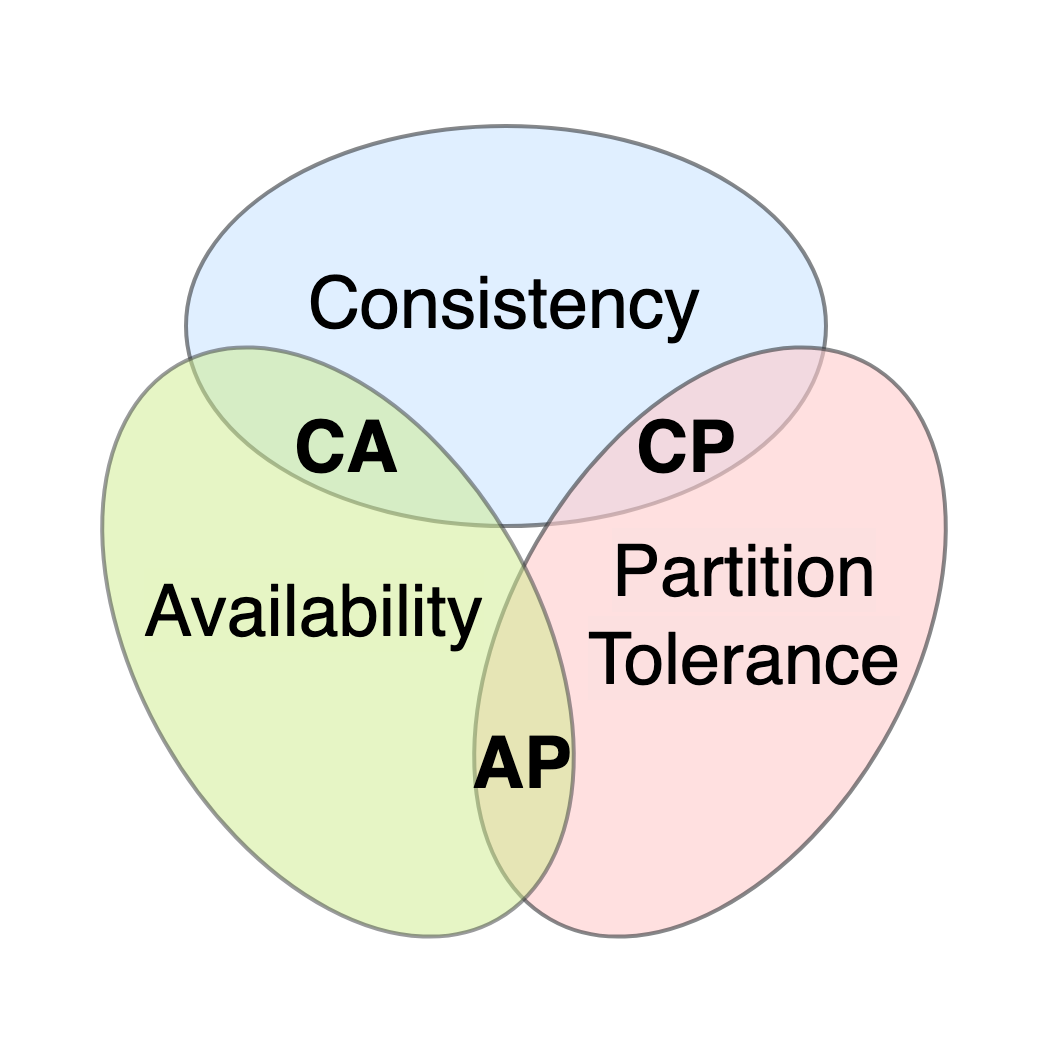

https://en.wikipedia.org/wiki/CAP_theorem

### ACID vs BASE


ACID и BASE – это две разные модели управления транзакциями в базах данных, каждая из которых акцентирует внимание на разных аспектах производительности и надежности.

ACID (Атомарность, Согласованность, Изолированность, Долговечность)

- Atomicity (либо выполнили транзакцию, либо обернули)

- Consitency (на всех машинах сразу)

- Isolation (есть порядок транзакции, они друг друга ждут если надо)

- Durability (после успешного завершения транзакции изменения данных будут сохранены даже в случае сбоя системы)


Гарантирует, что все операции в транзакции выполняются полностью и точно до ее фиксации, что поддерживает строгую согласованность данных. Эта модель идеально подходит для систем, где целостность данных крайне важна, например, в банковских системах. Однако она может вызывать проблемы с производительностью и сложнее масштабируется горизонтально.

BASE (Принципиальная доступность, Мягкое состояние, Окончательная согласованность)

- Basically available (мы что-то ответим, но не факт что идеально точно-согласовано)
- Soft State (изменения происходят сами по себе с течением времени)
- Eventually consistent (изменения однажды станут согласованны)

Приоритизирует доступность и допускает временные несогласованности, которые со временем устраняются, что делает её подходящей для систем, где немедленная согласованность не критична, например, социальных сетей и интернет-магазинов.

Основное различие между ACID и BASE заключается в том, как они управляют согласованностью и доступностью. ACID приоритизирует согласованность, но жертвует доступностью, гарантируя, что все узлы сразу видят одинаковые данные после транзакции. BASE, напротив, делает акцент на доступности, даже если данные могут временно быть несогласованными, что делает её подходящей для распределённых систем, где важна высокая доступность, и можно терпеть задержки в согласованности.

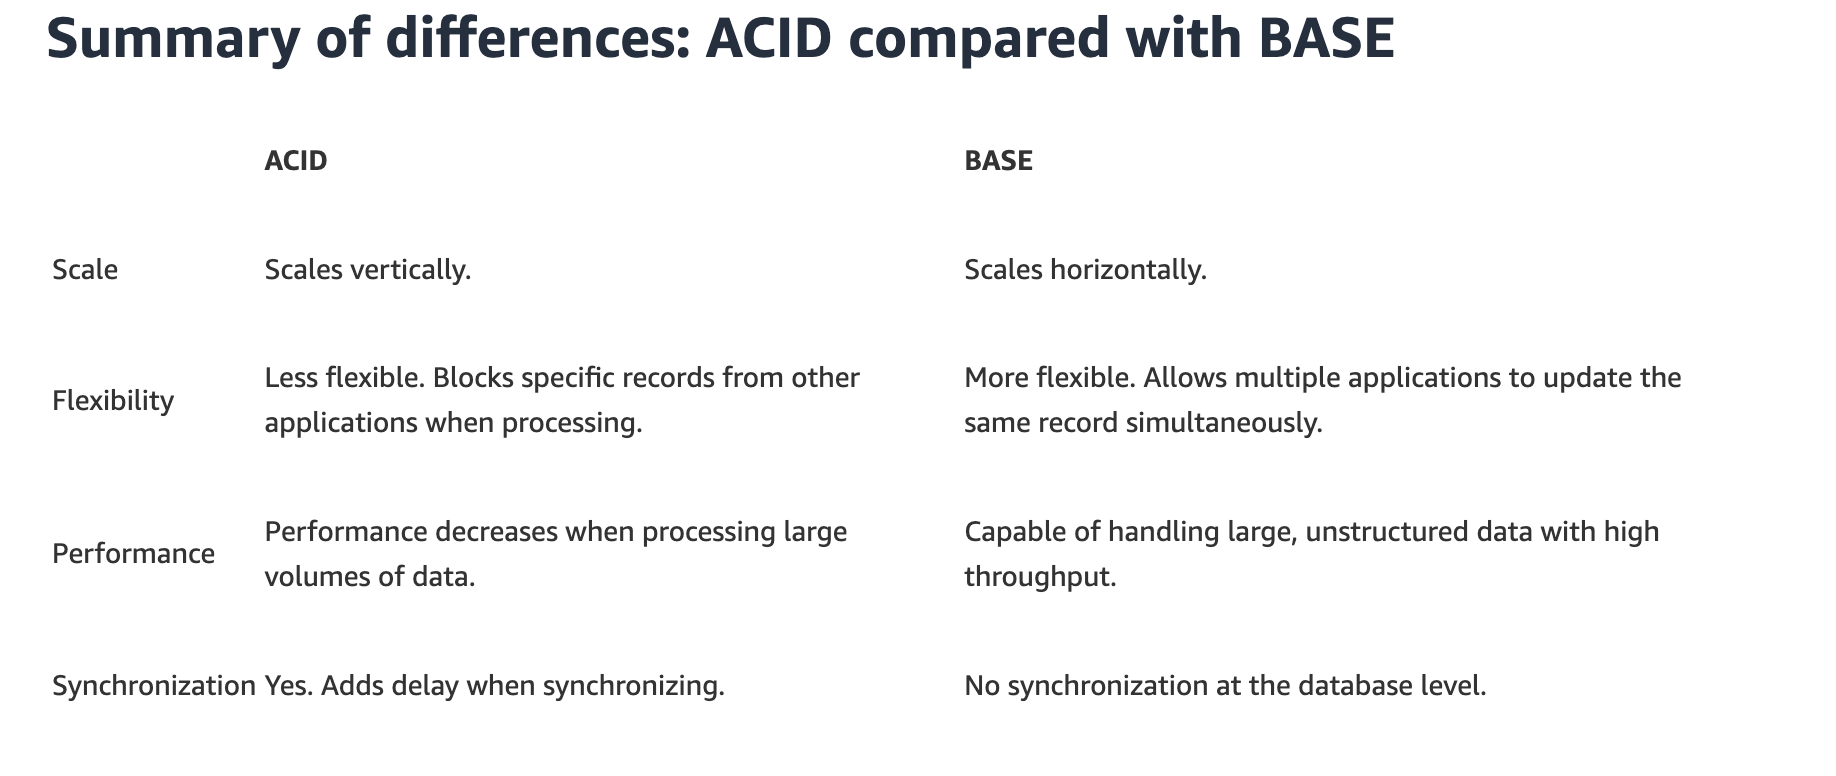

### Каcкадные операции

**на этом шаге ipynb необходимо перезапустить!**

Каскадные операции в алхимии позволяют автоматически выполнять действия с зависимыми объектами при изменении или удалении основного объекта. \
Например, можно автоматически удалить все связанные с объектом записи, если основной объект удаляется.

Давайте настроим это!

In [ ]:
from sqlalchemy import Column, Integer, String, ForeignKey, create_engine
from sqlalchemy.orm import relationship, sessionmaker
from sqlalchemy.ext.declarative import declarative_base

In [ ]:
Base = declarative_base()

/tmp/ipython-input-4196137762.py:1: MovedIn20Warning: The ``declarative_base()`` function is now available as sqlalchemy.orm.declarative_base(). (deprecated since: 2.0) (Background on SQLAlchemy 2.0 at: https://sqlalche.me/e/b8d9)
  Base = declarative_base()


In [ ]:
class Artist(Base):
    __tablename__ = 'artists'

    ArtistId = Column(Integer, primary_key=True)
    Name = Column(String)
    # отношение "Один артист" - "Много альбомов"
    # здесь мы говорим, что если мы удаляем артиста, то также удаляй все его альбомы
    albums = relationship('Album', back_populates='artist', cascade='all, delete')

In [ ]:
class Album(Base):
    __tablename__ = 'albums'

    AlbumId = Column(Integer, primary_key=True)
    Title = Column(String)
    ArtistId = Column(Integer, ForeignKey('artists.ArtistId'))

    artist = relationship('Artist', back_populates='albums') # не нужно описывать зависимость во второй таблице

In [ ]:
engine = create_engine('sqlite:///chinook.db')
Session = sessionmaker(bind=engine)
session = Session()

In [ ]:
new_artist = Artist(Name="Артист Артистович")
new_album1 = Album(Title="Первый альбом", artist=new_artist)
new_album2 = Album(Title="Второй альбом", artist=new_artist)

In [ ]:
session.add(new_artist)
session.commit()

In [ ]:
print("Добавили артиста и его альбомы!")
artist = session.query(Artist).filter_by(Name="Артист Артистович").first()
print(f"Новый артист: {artist.Name}")
for album in artist.albums:
    print(f"\t- Альбомы: {album.Title}")

Добавили артиста и его альбомы!
Новый артист: Артист Артистович
	- Альбомы: Первый альбом
	- Альбомы: Второй альбом


In [ ]:
# откатим назад
session.delete(artist)
session.commit()

In [ ]:
deleted_artist = session.query(Artist).filter_by(Name="Артист Артистович").first()
deleted_albums = session.query(Album).filter(Album.Title.in_(["Первый альбом", "Второй альбом"])).all()

print("Артист:", deleted_artist)
print("Его альбомы: ", deleted_albums)

Артист: None
Его альбомы:  []


### А что если генерировать ORM модели?

(запускайте это локально!!!)

`sqlacodegen` — это вспомогательная утилита для SQLAlchemy, которая генерирует Python-код моделей ORM или Core на основе уже существующей базы данных.

Используется в основном для дебага или по другим причинам, когда не хочется писать свои модели

In [ ]:
!pip install sqlacodegen

In [ ]:
!sqlacodegen sqlite:///chinook.db --outfile models.py

In [ ]:
! cat models.py

from sqlalchemy import Column, DateTime, ForeignKey, Index, Integer, NVARCHAR, Numeric, Table
from typing import Optional
import datetime
import decimal

from sqlalchemy.orm import DeclarativeBase, Mapped, mapped_column, relationship

class Base(DeclarativeBase):
    pass


class Artists(Base):
    __tablename__ = 'artists'

    ArtistId: Mapped[int] = mapped_column(Integer, primary_key=True)
    Name: Mapped[Optional[str]] = mapped_column(NVARCHAR(120))

    albums: Mapped[list['Albums']] = relationship('Albums', back_populates='artists')


class Employees(Base):
    __tablename__ = 'employees'
    __table_args__ = (
        Index('IFK_EmployeeReportsTo', 'ReportsTo'),
    )

    EmployeeId: Mapped[int] = mapped_column(Integer, primary_key=True)
    LastName: Mapped[str] = mapped_column(NVARCHAR(20), nullable=False)
    FirstName: Mapped[str] = mapped_column(NVARCHAR(20), nullable=False)
    Title: Mapped[Optional[str]] = mapped_column(NVARCHAR(30))
    ReportsTo: Mapped[Optional[int]

In [ ]:
from models import Artist

new_artist = Artist(Name="Артист Артистович")
session.add(new_artist)


artist = session.query(Artist).filter_by(Name="Артист Артистович").first()
print("Найдет артист:", artist)

ImportError: cannot import name 'Artist' from 'models' (/content/models.py)